In [ ]:
!pip install -U transformers torchvision accelerate pycocotools tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 145.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 129.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 73.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.3/39.3 MB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import json, os
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


Device: cuda


In [ ]:
from transformers import DetrForObjectDetection, DetrImageProcessor

processor = DetrImageProcessor.from_pretrained(
    "facebook/detr-resnet-50"
)

model = DetrForObjectDetection.from_pretrained(
    "facebook/detr-resnet-50",
    num_labels=1,                 # single class: corrosion
    ignore_mismatched_sizes=True
).to(device)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for bn1.bias: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pas

In [ ]:
class CocoDetectionDETR(Dataset):
    def __init__(self, img_dir, ann_file, processor):
        self.img_dir = img_dir
        self.processor = processor

        with open(ann_file, "r") as f:
            coco = json.load(f)

        self.images = coco["images"]
        self.annotations = coco["annotations"]

        # group annotations per image
        self.ann_per_image = {}
        for ann in self.annotations:
            img_id = ann["image_id"]
            self.ann_per_image.setdefault(img_id, []).append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_info = self.images[idx]
        image_id = img_info["id"]

        img_path = os.path.join(self.img_dir, img_info["file_name"])
        image = Image.open(img_path).convert("RGB")

        anns = self.ann_per_image.get(image_id, [])

        # Skip images without annotations
        if len(anns) == 0:
            return self.__getitem__((idx + 1) % len(self.images))

        valid_anns = []
        for ann in anns:
            bbox = ann.get("bbox", None)
            if bbox is None or len(bbox) != 4:
                continue

            x, y, w, h = bbox
            if w <= 0 or h <= 0:
                continue

            valid_anns.append({
                "bbox": [float(x), float(y), float(w), float(h)],
                "category_id": 0,          # force single class
                "area": float(w * h),
                "iscrowd": 0
            })

        if len(valid_anns) == 0:
            return self.__getitem__((idx + 1) % len(self.images))

        target = {
            "image_id": image_id,
            "annotations": valid_anns
        }

        encoding = self.processor(
            images=image,
            annotations=target,
            return_tensors="pt"
        )

        pixel_values = encoding["pixel_values"].squeeze(0)
        labels = encoding["labels"][0]

        return pixel_values, labels


In [ ]:
train_dataset = CocoDetectionDETR(
    img_dir="/content/drive/MyDrive/DatasetKorosi_COCO/train/images",
    ann_file="/content/drive/MyDrive/DatasetKorosi_COCO/train/_annotations.coco.json",
    processor=processor
)

val_dataset = CocoDetectionDETR(
    img_dir="/content/drive/MyDrive/DatasetKorosi_COCO/valid/images",
    ann_file="/content/drive/MyDrive/DatasetKorosi_COCO/valid/_annotations.coco.json",
    processor=processor
)

print("Train samples:", len(train_dataset))
print("Val samples:", len(val_dataset))


Train samples: 5526
Val samples: 521


In [ ]:
sample = train_dataset[0]

print("Pixel values shape:", sample[0].shape)
print("Label keys:", sample[1].keys())
print("Boxes shape:", sample[1]["boxes"].shape)
print("Class labels:", sample[1]["class_labels"])


Pixel values shape: torch.Size([3, 800, 800])
Label keys: KeysView({'size': tensor([800, 800]), 'image_id': tensor([0]), 'class_labels': tensor([0]), 'boxes': tensor([[0.2910, 0.1809, 0.3852, 0.2680]]), 'area': tensor([66054.2969]), 'iscrowd': tensor([0]), 'orig_size': tensor([640, 640])})
Boxes shape: torch.Size([1, 4])
Class labels: tensor([0])


In [ ]:
def detr_collate_fn(batch):
    pixel_values = [item[0] for item in batch]
    labels = [item[1] for item in batch]

    pixel_values = torch.stack(pixel_values)
    return pixel_values, labels


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    collate_fn=detr_collate_fn   # 🔥 PENTING
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    collate_fn=detr_collate_fn
)


In [ ]:
import torch.optim as optim

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4
)

epochs = 15   # cukup untuk Transformer context learning


In [ ]:
for epoch in range(epochs):
    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

    for pixel_values, labels in loop:
        pixel_values = pixel_values.to(device)
        labels = [{k: v.to(device) for k, v in t.items()} for t in labels]

        outputs = model(
            pixel_values=pixel_values,
            labels=labels
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loop.set_postfix(loss=loss.item())


    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1} | Avg Loss: {avg_loss:.4f}")


Epoch 1/15:   3%|▎         | 39/1382 [01:14<44:24,  1.98s/it, loss=1.04]Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78c82af9dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1654, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1637, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Epoch 1/15:   3%|▎         | 46/1382 [01:25<35:06,  1.58s/it, loss=3.43]Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78c82af9dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.

Epoch 1 | Avg Loss: 0.0000


Epoch 2/15: 100%|██████████| 1382/1382 [03:07<00:00,  7.38it/s, loss=2.75]


Epoch 2 | Avg Loss: 0.0000


Epoch 3/15: 100%|██████████| 1382/1382 [03:07<00:00,  7.39it/s, loss=2.29]


Epoch 3 | Avg Loss: 0.0000


... (20 outputs left out)

Epoch 14/15: 100%|██████████| 1382/1382 [03:06<00:00,  7.40it/s, loss=2.81]


Epoch 14 | Avg Loss: 0.0000


Epoch 15/15: 100%|██████████| 1382/1382 [03:07<00:00,  7.38it/s, loss=0.0642]

Epoch 15 | Avg Loss: 0.0000


In [ ]:
save_dir = "/content/drive/MyDrive/CV_Corrosion_Project/Transformer_DETR_2"
model.save_pretrained(save_dir)
processor.save_pretrained(save_dir)

print(f"✅ Transformer DETR model saved to: {save_dir}")



✅ Transformer DETR model saved to: /content/drive/MyDrive/CV_Corrosion_Project/Transformer_DETR_2


In [ ]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    },
    "/content/drive/MyDrive/CV_Corrosion_Project/Transformer_DETR_checkpoint.pth"
)

print("✅ PyTorch checkpoint saved")


✅ PyTorch checkpoint saved


UJI DETR

In [ ]:
import torch
from transformers import DetrForObjectDetection, DetrImageProcessor
from PIL import Image
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

model_dir = "/content/drive/MyDrive/CV_Corrosion_Project/Transformer_DETR_2"

processor = DetrImageProcessor.from_pretrained(model_dir)
model = DetrForObjectDetection.from_pretrained(model_dir).to(device)

model.eval()
print("✅ DETR model loaded")


✅ DETR model loaded


In [ ]:
image_path = "/content/drive/MyDrive/DatasetKorosi_COCO/test/images/2-Examples-of-crevice-corrosion-damage-on-Type-316-stainless-steels-in-chloride_png_jpg.rf.6e6e9441a0a98861e0b53cd3f37337e7.jpg"

image = Image.open(image_path).convert("RGB")


In [ ]:
inputs = processor(images=image, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(**inputs)


In [ ]:
target_sizes = torch.tensor([image.size[::-1]]).to(device)

results = processor.post_process_object_detection(
    outputs,
    threshold=0.3,              # confidence threshold
    target_sizes=target_sizes
)[0]

print("Detected boxes:", len(results["boxes"]))


Detected boxes: 0


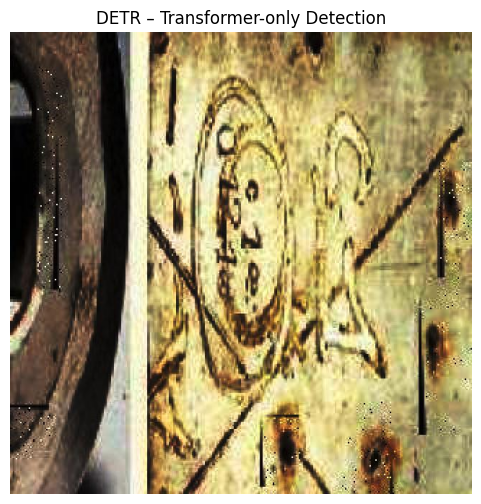

In [ ]:
import cv2
import numpy as np

img = np.array(image)

for score, box in zip(results["scores"], results["boxes"]):
    x1, y1, x2, y2 = box.cpu().numpy().astype(int)

    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(
        img,
        f"corrosion {score:.2f}",
        (x1, y1 - 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title("DETR – Transformer-only Detection")
plt.show()


In [ ]:
import json
import torch
from tqdm import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


In [ ]:
gt_ann = "/content/drive/MyDrive/DatasetKorosi_COCO/test/_annotations.coco.json"
coco_gt = COCO(gt_ann)


loading annotations into memory...
Done (t=0.88s)
creating index...
index created!


In [ ]:
predictions = []

model.eval()

image_dir = "/content/drive/MyDrive/DatasetKorosi_COCO/test/images"

for img_info in tqdm(coco_gt.dataset["images"]):
    img_id = img_info["id"]
    img_path = f"{image_dir}/{img_info['file_name']}"

    image = Image.open(img_path).convert("RGB")
    inputs = processor(images=image, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    target_sizes = torch.tensor([image.size[::-1]]).to(device)

    results = processor.post_process_object_detection(
        outputs,
        threshold=0.05,
        target_sizes=target_sizes
    )[0]

    for score, box in zip(results["scores"], results["boxes"]):
        x1, y1, x2, y2 = box.cpu().numpy()
        w = x2 - x1
        h = y2 - y1

        predictions.append({
            "image_id": img_id,
            "category_id": 0,       # corrosion
            "bbox": [float(x1), float(y1), float(w), float(h)], # COCO format
            "score": float(score)
        })


100%|██████████| 262/262 [00:22<00:00, 11.57it/s]


In [ ]:
pred_path = "/content/drive/MyDrive/CV_Corrosion_Project/detr_predictions.json"

with open(pred_path, "w") as f:
    json.dump(predictions, f)

print("✅ Predictions saved")


✅ Predictions saved


In [ ]:
coco_dt = coco_gt.loadRes(pred_path)

coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()


Loading and preparing results...
DONE (t=10.56s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.19s).
Accumulating evaluation results...
DONE (t=0.05s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

In [ ]:
print(coco_gt.dataset["categories"])


[{'id': 0, 'name': 'corrosion', 'supercategory': 'none'}, {'id': 1, 'name': 'corrosion', 'supercategory': 'corrosion'}]


In [ ]:
cat_id = 0


In [ ]:
predictions.append({
    "image_id": img_id,
    "category_id": 0,   # 🔥 PAKAI INI
    "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
    "score": float(score)
})


In [ ]:
import json

ann_path = "/content/drive/MyDrive/DatasetKorosi_COCO/test/_annotations.coco.json"
fixed_ann_path = "/content/drive/MyDrive/DatasetKorosi_COCO/test/_annotations_fixed.coco.json"

with open(ann_path, "r") as f:
    coco = json.load(f)

# 1️⃣ Ambil hanya category id = 0
coco["categories"] = [
    cat for cat in coco["categories"] if cat["id"] == 0
]

# 2️⃣ Ambil hanya annotation dengan category_id = 0
coco["annotations"] = [
    ann for ann in coco["annotations"] if ann["category_id"] == 0
]

with open(fixed_ann_path, "w") as f:
    json.dump(coco, f)

print("✅ COCO annotation fixed (category_id=0 only)")


✅ COCO annotation fixed (category_id=0 only)


In [ ]:
from pycocotools.coco import COCO

coco_gt = COCO(fixed_ann_path)


loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


In [ ]:
coco_dt = coco_gt.loadRes(pred_path)

from pycocotools.cocoeval import COCOeval

coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()


Loading and preparing results...
DONE (t=0.12s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.16s).
Accumulating evaluation results...
DONE (t=0.04s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | m

In [ ]:
print("Total predictions:", len(predictions))


Total predictions: 26201


HYBRID

In [ ]:
!pip install ensemble-boxes


In [ ]:
!pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 34.7 MB/s eta 0:00:00


In [ ]:
import torch
from ultralytics import YOLO
from transformers import DetrForObjectDetection, DetrImageProcessor
from PIL import Image
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"

# CNN (YOLOv8)
yolo = YOLO("/content/drive/MyDrive/CV_Corrosion_Project/CNN_only/weights/best.pt")

# Transformer (DETR)
detr_dir = "/content/drive/MyDrive/CV_Corrosion_Project/Transformer_DETR_2"
processor = DetrImageProcessor.from_pretrained(detr_dir)
detr = DetrForObjectDetection.from_pretrained(detr_dir).to(device)
detr.eval()


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for bn1.bias: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pas

DetrForObjectDetection(
  (model): DetrModel(
    (backbone): DetrConvModel(
      (conv_encoder): DetrConvEncoder(
        (model): FeatureListNet(
          (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
          (bn1): DetrFrozenBatchNorm2d()
          (act1): ReLU(inplace=True)
          (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
          (layer1): Sequential(
            (0): Bottleneck(
              (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (bn1): DetrFrozenBatchNorm2d()
              (act1): ReLU(inplace=True)
              (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
              (bn2): DetrFrozenBatchNorm2d()
              (drop_block): Identity()
              (act2): ReLU(inplace=True)
              (aa): Identity()
              (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      

In [ ]:
def yolo_predict(image_path, conf=0.25):
    result = yolo(image_path, conf=conf)[0]

    boxes = []
    scores = []
    labels = []

    h, w = result.orig_shape

    for box, score in zip(result.boxes.xyxy, result.boxes.conf):
        x1, y1, x2, y2 = box.cpu().numpy()

        boxes.append([
            x1 / w, y1 / h, x2 / w, y2 / h
        ])
        scores.append(float(score))
        labels.append(0)  # corrosion

    return boxes, scores, labels


In [ ]:
def detr_predict(image_path, conf=0.05):
    image = Image.open(image_path).convert("RGB")
    w, h = image.size

    inputs = processor(images=image, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = detr(**inputs)

    results = processor.post_process_object_detection(
        outputs,
        threshold=conf,
        target_sizes=torch.tensor([[h, w]]).to(device)
    )[0]

    boxes = []
    scores = []
    labels = []

    for box, score in zip(results["boxes"], results["scores"]):
        x1, y1, x2, y2 = box.cpu().numpy()

        boxes.append([
            x1 / w, y1 / h, x2 / w, y2 / h
        ])
        scores.append(float(score))
        labels.append(0)

    return boxes, scores, labels


In [ ]:
from ensemble_boxes import weighted_boxes_fusion

def hybrid_wbf(image_path):
    y_boxes, y_scores, y_labels = yolo_predict(image_path)
    d_boxes, d_scores, d_labels = detr_predict(image_path)

    boxes, scores, labels = weighted_boxes_fusion(
        [y_boxes, d_boxes],
        [y_scores, d_scores],
        [y_labels, d_labels],
        weights=[2, 1],        # CNN lebih dominan
        iou_thr=0.5,
        skip_box_thr=0.05
    )

    return boxes, scores, labels


In [ ]:
import cv2
import matplotlib.pyplot as plt

def visualize_hybrid(image_path):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape

    boxes, scores, _ = hybrid_wbf(image_path)

    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = box
        x1, y1 = int(x1 * w), int(y1 * h)
        x2, y2 = int(x2 * w), int(y2 * h)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0,255,0), 2)
        cv2.putText(image, f"Hybrid {score:.2f}", (x1, y1-5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,0,0), 2)

    plt.figure(figsize=(6,6))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Hybrid CNN–Transformer (YOLO + DETR + WBF)")
    plt.show()



image 1/1 /content/drive/MyDrive/20220140171_D/12.-Bahaya-Karat-Besi-bagi-Tubuh.webp: 352x640 1 corrosion, 111.3ms
Speed: 10.3ms preprocess, 111.3ms inference, 43.8ms postprocess per image at shape (1, 3, 352, 640)


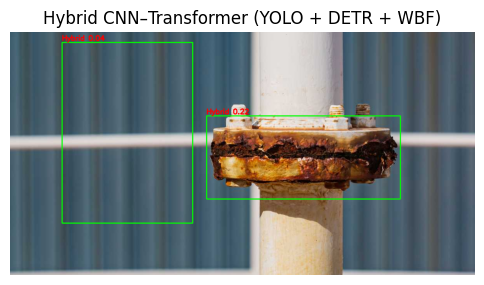

In [ ]:
test_img = "/content/drive/MyDrive/20220140171_D/12.-Bahaya-Karat-Besi-bagi-Tubuh.webp"
visualize_hybrid(test_img)


In [ ]:
from pycocotools.coco import COCO

gt_ann = "/content/drive/MyDrive/DatasetKorosi_COCO/test/_annotations_fixed.coco.json"
coco_gt = COCO(gt_ann)

print("Categories:", coco_gt.dataset["categories"])


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Categories: [{'id': 0, 'name': 'corrosion', 'supercategory': 'none'}]


In [ ]:
import json
from tqdm import tqdm

hybrid_predictions = []

image_dir = "/content/drive/MyDrive/DatasetKorosi_COCO/test/images"

for img_info in tqdm(coco_gt.dataset["images"]):
    img_id = int(img_info["id"])
    img_path = f"{image_dir}/{img_info['file_name']}"

    boxes, scores, labels = hybrid_wbf(img_path)

    # ambil ukuran gambar
    image = Image.open(img_path)
    w, h = image.size

    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = box

        hybrid_predictions.append({
            "image_id": img_id,
            "category_id": 0,  # corrosion
            "bbox": [
                float(x1 * w),
                float(y1 * h),
                float((x2 - x1) * w),
                float((y2 - y1) * h)
            ],
            "score": float(score)
        })


  0%|          | 0/262 [00:00<?, ?it/s]


image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/GEN_379_jpg.rf.037fc7a4cfb37e6cdb7e70406911482a.jpg: 640x640 (no detections), 8.8ms
Speed: 2.1ms preprocess, 8.8ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)


  0%|          | 1/262 [00:00<00:39,  6.66it/s]


image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/ec961492e1_jpg.rf.032db657dcee597f2735d10af985ab68.jpg: 640x640 1 corrosion, 7.7ms
Speed: 1.7ms preprocess, 7.7ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


  1%|          | 2/262 [00:00<00:39,  6.67it/s]


image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/CM21_png_jpg.rf.03a47974b395efadacdcd469393e9d5b.jpg: 640x640 1 corrosion, 9.7ms
Speed: 2.0ms preprocess, 9.7ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)


... (515 outputs left out)


image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/Captura-de-Tela-2023-01-25-a-s-18-27-58_png_jpg.rf.efa17b6b2db665e8e5d032db8e89c521.jpg: 640x640 1 corrosion, 7.8ms
Speed: 1.7ms preprocess, 7.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


100%|█████████▉| 261/262 [00:38<00:00,  6.92it/s]


image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/L35_jpg.rf.d9e6292261dd8df57444b9f1f23ab14d.jpg: 640x640 1 corrosion, 7.8ms
Speed: 1.7ms preprocess, 7.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


100%|██████████| 262/262 [00:38<00:00,  6.77it/s]


In [ ]:
hybrid_pred_path = "/content/drive/MyDrive/CV_Corrosion_Project/hybrid_predictions.json"

with open(hybrid_pred_path, "w") as f:
    json.dump(hybrid_predictions, f)

print("✅ Hybrid predictions saved")
print("Total hybrid predictions:", len(hybrid_predictions))


✅ Hybrid predictions saved
Total hybrid predictions: 528


In [ ]:
from pycocotools.cocoeval import COCOeval

coco_dt = coco_gt.loadRes(hybrid_pred_path)

coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()


Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.04s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | m

In [ ]:
def compute_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    inter = max(0, xB - xA) * max(0, yB - yA)
    areaA = (boxA[2]-boxA[0]) * (boxA[3]-boxA[1])
    areaB = (boxB[2]-boxB[0]) * (boxB[3]-boxB[1])

    union = areaA + areaB - inter
    return inter / union if union > 0 else 0


In [ ]:
IOU_THRESHOLD = 0.3  # 🔥 lebih realistis untuk korosi

TP, FP, FN = 0, 0, 0
ious = []

for img_info in coco_gt.dataset["images"]:
    img_id = img_info["id"]

    gt_boxes = [
        ann["bbox"] for ann in coco_gt.imgToAnns[img_id]
    ]

    # convert GT to xyxy
    gt_boxes = [
        [x, y, x+w, y+h] for x, y, w, h in gt_boxes
    ]

    # hybrid prediction
    boxes, scores, _ = hybrid_wbf(
        f"{image_dir}/{img_info['file_name']}"
    )

    pred_boxes = [
        [b[0]*w, b[1]*h, b[2]*w, b[3]*h] for b in boxes
    ]

    matched = [False]*len(gt_boxes)

    for pb in pred_boxes:
        found = False
        for i, gb in enumerate(gt_boxes):
            iou = compute_iou(pb, gb)
            if iou >= IOU_THRESHOLD and not matched[i]:
                TP += 1
                matched[i] = True
                ious.append(iou)
                found = True
                break
        if not found:
            FP += 1

    FN += matched.count(False)



image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/GEN_379_jpg.rf.037fc7a4cfb37e6cdb7e70406911482a.jpg: 640x640 (no detections), 8.9ms
Speed: 2.0ms preprocess, 8.9ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/ec961492e1_jpg.rf.032db657dcee597f2735d10af985ab68.jpg: 640x640 1 corrosion, 8.7ms
Speed: 1.7ms preprocess, 8.7ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/CM21_png_jpg.rf.03a47974b395efadacdcd469393e9d5b.jpg: 640x640 1 corrosion, 8.9ms
Speed: 2.0ms preprocess, 8.9ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/drive/MyDrive/DatasetKorosi_COCO/test/images/painted-iron-background-with-a-large-stock-photograph_csp82020592_jpg.rf.0631db7afe0f760bce290712e765ff52.jpg: 640x640 1 corrosion, 7.6ms
Speed: 1.7ms preprocess, 7.6ms inference, 1.5ms postprocess per im

In [ ]:
precision = TP / (TP + FP + 1e-6)
recall = TP / (TP + FN + 1e-6)
f1 = 2 * precision * recall / (precision + recall + 1e-6)
mean_iou = sum(ious) / len(ious) if ious else 0

print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1-score: {f1:.3f}")
print(f"Mean IoU: {mean_iou:.3f}")


Precision: 0.000
Recall: 0.000
F1-score: 0.000
Mean IoU: 0.000
